<a href="https://colab.research.google.com/github/nohyunkim/AuditTrail/blob/main/AA12/aa12-m1-question-notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**AICE Associate <font color=red>모의고사 (문제)</font>** — AICE_Asso_006_공식형_다중분류_농산물도매시세

### **농산물 도매 시세 — <span style="color:darkgreen">시세 추세</span> 예측 모델 개발**
---

- 도메인 : 농산물 도매 시세
- 목  표 : 다음 주 도매 시세 추세(하락/보합/상승)를 예측하는 인공지능모델 개발
- 기상과 반입 물량에 따라 가격이 크게 출렁여 정성그린의 매입 계획 수립이 어렵다.
- 구매팀은 기상·수급 데이터로 시세를 예측해 매입 시점을 최적화하려 한다.
- 분석에는 약 780건 규모의 출하 건 데이터가 제공된다.
- 모델이 시세 추세를 신뢰할 만한 수준으로 예측하면 현업의 대응 비용을 줄일 수 있을 것으로 기대한다.

---

#### **[유의사항]**
- 답안 형태는 두 가지입니다. ① **결과 변수 저장형** — 가이드가 지정한 변수(예: `X_train`, `model`)에 결과를 저장하면 그 변수의 내용으로 채점합니다. ② **정답 입력형** — 코드 셀 **맨 아래** `정답NN`(빈칸이 여럿이면 `정답NN_1`, `정답NN_2`) 변수에 **값만** 입력합니다.
- 맨 위 **자동 채점 준비** 셀을 먼저 실행하면, 문항마다 `채점(번호)` 셀로 바로 ✅/❌ 를 확인하고 맨 끝 `채점()` 셀로 총점을 볼 수 있습니다.
- 숫자는 문항이 안내한 자릿수로 반올림해 입력하고, 글자는 따옴표로 감싸 입력하세요(예: `정답01 = 'pandas'`).
- 답을 구하는 코드는 문항의 작업 셀에 작성하고 실행하세요. 제공된 문항 셀을 삭제하지 마세요.
- 문항에 변수명이 제시된 경우 반드시 해당 변수명을 사용하세요. 앞 문항의 결과를 뒤 문항이 이어서 사용합니다.
- 막히면 문항 아래 접혀 있는 **힌트 1·2·3단계**를 순서대로 펼쳐 보세요. 단계가 올라갈수록 정답에 가까워집니다.
- 모든 데이터는 가상으로 생성한 합성데이터이며, 실제 AICE 시험문항의 원문을 복제하지 않았습니다.

#### **[학습 정보]**
- 학습 목표 : 정성그린의 데이터로 다음 주 도매 시세 추세(하락/보합/상승)를 예측하는 AI 모델을 만들며 데이터 분석·전처리·모델링 전 과정을 수행할 수 있다
- AICE 역량 : 데이터 분석(DA1 분석 환경 구성, DA2 데이터 불러오기·구조 파악, DA3 탐색적 데이터 분석, DA4 데이터 시각화) / 데이터 전처리(DP1 이상치 처리, DP2 결측치 처리, DP3 인코딩·변수 변환, DP4 데이터 분할, DP5 스케일링) / AI 모델링(AM1 머신러닝 모델 학습·탐색, AM2 모델 해석, AM3 모델 성능 평가, AM4 딥러닝 모델 구성·학습, AM5 딥러닝 학습 결과 분석)
- 기술 스택 : pandas(import pandas as pd, read_csv, head, value_counts, dtypes, corr, quantile, drop, reset_index, dropna, sum, isnull, copy, get_dummies, Series, idxmax, columns, shape) · seaborn(heatmap) · matplotlib(show, plot, title, xlabel, ylabel, legend) · scikit-learn(OrdinalEncoder, fit_transform, train_test_split, MinMaxScaler, transform, KNeighborsClassifier, fit, RandomForestClassifier, feature_importances_, predict, accuracy_score) · TensorFlow(Keras)(to_categorical, Input, Model, EarlyStopping, compile, fit, Dense, BatchNormalization, Dropout, history)
- 난이도 : 공식형(중급) (설계 난이도 점수 2.75 / 5)
- 예상 소요 시간 : 약 121분 (문항별 시간은 각 문항 제목 아래)
- 관련 도메인 : 농산물 도매 시세 (농업·식품)

**[ 데이터 컬럼 설명 (데이터 파일명: data.csv) ]**

- priceTrend            : 시세 추세 (0: Down, 1: Flat, 2: Up)
- sampleId              : 표본 식별번호
- rainfallMm            : 최근 4주 강수량(mm)
- sunshineH             : 최근 4주 일조시간(h)
- tempAvg               : 평균 기온(℃)
- supplyTon             : 반입 물량(톤)
- stockTon              : 저장 재고(톤)
- importTon             : 수입 물량(톤)
- demandIdx             : 수요 지수
- fuelCost              : 산지 유류비 지수
- holidayDays           : 인접 공휴일 수
- pestIdx               : 병해충 발생 지수
- origin                : 산지
- grade                 : 등급
- market                : 도매시장
- sizeClass             : 규모 구분

> **<span style="color:red">자동 채점 준비</span>** — 아래 셀을 먼저 실행하세요. 정답 키는 압축·인코딩되어 있습니다.

In [1]:
# 자동 채점 준비 — 이 셀을 먼저 실행하세요. 문항마다 아래 `채점(번호)` 셀을 실행하면 ✅/❌ 로 바로 확인할 수 있습니다.
import base64 as _b64, json as _json, zlib as _zlib
_정답키 = _json.loads(_zlib.decompress(_b64.b64decode("eNqllsGOmzAQhl/F4gJIqWVDEkilnFpV6rWnlaIIuTA0aI2hNmkTrfYJeu69L9Gnah+iNqQNZIFY6il4PP7+8YzHzu7JEZXzGtEFch4LkelPhwn1FaSjLV+YNIbfP77/+vaTUGOqq0I0SltXmOghS1OoGz3cOTUTGVPOXlubimsTeV6gCz7o4Q30ys7yEWp6gPTRDHdPjoE7cCqUntdTgpVwWdfi22l1YDXczLYS/GiGuygOF4iu99cVcKrbKNpfPZbVUWRezivWeKLGQufgWJovppiU7OxlOVbAIW2SrDnXoDxXHMuPIF0fFTk6aLemkdprgdyBn54HrgCZmdaybUV831+gwO9HSWm0iWKCl/8SSDHdbOLn/TWPoUWZwvkytXJJqvfbTBRraSGynBdJS1aPw1cW8FUyPGrhLf7zkYmm4PA/EsG8RCariR2sLfDrAXx9A6dhhMkoO7JgR/NsTMIeGhNKr/h4sg0fEn0uimwEbdGLD0kjWSGcfnu99OkE5nzOFpzzCw4HMSbU76wgnnHvNHvuq0vKRi8KnZv+tXAJB+ukwsnH5tLwB129XEerZb+FNxYl3syW+JWuajBZY0ruC1AyEKDkRoHgOI4HCoSuexIWrwWl8xJOBqV+MN5np/Euo4GFRnBH44NWqMp3lQTVGNf++A1nShV50XFlPhFGONkyZZUBHwvAomO6tXPn/KANlTw70yexZeD2Ik9qJlmpvOF7Em1W06t1G3g7jvJKIo4KgToaZ2eQyrxo5qnyuI+TxESUJGi7Re5bEArc/UAmmNa47AF30e1cqKv0oNz9YDkh/e6gFo8PXSZ3/or8Td54Se0kgnkJDp9AI/oK+z94Scmj")).decode("utf-8"))


def _같음(a, b, tol=0):
    try:
        if a is None or b is None:
            return a is None and b is None
        if isinstance(b, str) or isinstance(a, str):
            return str(a).strip().strip("'\"").replace(" ", "").lower() == str(b).strip().strip("'\"").replace(" ", "").lower()
        if isinstance(b, (list, tuple)):
            return len(a) == len(b) and all(_같음(x, y, tol) for x, y in zip(a, b))
        return abs(float(a) - float(b)) <= float(tol) + 1e-9
    except Exception:
        return False


def _검사(g, c):
    try:
        t, obj = c["t"], g.get(c.get("name"))
        if t == "exists":
            return c["name"] in g
        if t == "shape":
            return tuple(obj.shape) == tuple(c["value"])
        if t == "len":
            return len(obj) == c["value"]
        if t == "cols_have":
            return all(x in obj.columns for x in c["cols"])
        if t == "cols_lack":
            return all(x not in obj.columns for x in c["cols"])
        if t == "no_na":
            import pandas as _pd
            return int(_pd.DataFrame(obj).isna().sum().sum()) == 0
        if t == "all_numeric":
            import pandas as _pd
            d = _pd.DataFrame(obj)
            return all(_pd.api.types.is_numeric_dtype(d[x]) or _pd.api.types.is_bool_dtype(d[x]) for x in d.columns if x not in c.get("except", []))
        if t == "expr":
            return _같음(eval(c["expr"], g), c["value"], c.get("tol", 0))
        if t == "attr":
            return _같음(getattr(obj, c["attr"]), c["value"], c.get("tol", 0))
        if t == "has_attr":
            return hasattr(obj, c["attr"])
    except Exception:
        return False
    return False


_채점기록 = {}


def 채점(번호=None):
    """번호를 주면 그 문항만, 없으면 전체 문항을 채점해 점수를 보여 줍니다.
    결과 변수 저장형은 그 문항 바로 뒤의 `채점(번호)` 결과를 기억해 둡니다(뒤 문항이 같은 변수를 바꿀 수 있어서)."""
    g = globals()
    대상 = [k for k in _정답키 if 번호 is None or k["no"] == 번호]
    점수 = 0.0
    for k in 대상:
        if k["kind"] == "var":
            지금 = k["var"] in g and all(_검사(g, c) for c in k["checks"])
            if 번호 is not None:
                _채점기록[k["no"]] = 지금
            ok = _채점기록.get(k["no"], 지금) if 번호 is None else 지금
            무엇 = f"변수 `{k['var']}`"
        else:
            v = g.get(k["var"])
            ok = v is not None and any(_같음(v, a, k.get("tol", 0)) for a in k["accept"])
            무엇 = f"`{k['var']}`"
        점수 += k["points"] if ok else 0
        print(f"{'✅' if ok else '❌'} {k['no']}번 ({k['points']:g}점) — {무엇} {'정답' if ok else '다시 확인하세요'}")
    if 번호 is None:
        print(f"\n총점: {점수:g} / {sum(k['points'] for k in _정답키):g}")
    return 점수


## <font color=blue>**<데이터 분석 (20점)>**</font>

> **<span style="color:red">다음 문항을 풀기 전에 </span>아래 코드를 실행하세요.**

In [2]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

### **1. 데이터 분석을 위해 pandas 라이브러리를 사용하려고 합니다. 아래 가이드의 별칭(alias)으로 불러오세요.**

<sub>학습 목표: 분석에 필요한 파이썬 라이브러리를 관용 별칭으로 불러올 수 있다 | 역량: DA1 분석 환경 구성 | 기술: pandas(import pandas as pd) | 난이도: 기초 | 예상 시간: 3분</sub>

- 사용할 라이브러리 : `pandas`
- as 뒤에 쓸 이름(alias) : `pd`
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답01]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답01]** 의 값만 코드 셀 맨 아래에 `정답01 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

In [3]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

import pandas as pd


In [ ]:
# (1) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요

정답01 = 'pandas'


<details><summary>힌트 1단계 (접근 방향) - 1번 문항</summary>

`import 라이브러리 as 별칭` 문법으로 라이브러리를 불러옵니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 1번 문항</summary>

사용할 도구: `import ... as ...`. 정답은 6글자이고 첫 글자는 `p` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 1번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import pan___ as pd

정답01 = 'pan___'   # 빈칸에 넣은 단어
```

</details>

### **2. AI 모델링을 위해 분석 및 처리할 데이터 파일을 읽어오려고 합니다. pandas로 데이터 파일을 읽어온 뒤, 데이터프레임 변수명 df 에 할당하고 첫 6개 행을 출력하세요.**

<sub>학습 목표: CSV 파일을 데이터프레임으로 읽고 행·열 구성을 확인할 수 있다 | 역량: DA2 데이터 불러오기·구조 파악 | 기술: pandas(read_csv, head) | 난이도: 쉬움 | 예상 시간: 6분</sub>

- 앞 문항 결과 사용 : 1번 `pd`
- 제시된 가이드에 맞춰 코드를 작성하고 실행하세요
    - 대상 파일 : data.csv
    - 파일은 본 문제/답안지와 동일한 경로에 있습니다
    - 저장할 변수 이름 : df
    - 컬럼 구분자는 세미콜론(;) 입니다
- **[결과 변수]** 결과는 반드시 `df` 변수에 저장하세요 — 변수의 내용(모양·값)으로 채점합니다
- 확인 : 코드 셀 맨 아래 확인 줄(`print(df.shape)`)을 실행하세요. LMS 에서는 이 출력값을 입력합니다
- 배점 : 5점

---

In [9]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

df = pd.read_csv('./aa22-m1-data.csv', sep=';')
df.head(6)

print(df.shape)

(783, 16)


In [ ]:
# (2) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
'(783, 16)'

<details><summary>힌트 1단계 (접근 방향) - 2번 문항</summary>

파일 형식(csv/json/구분자)에 맞는 pandas 읽기 함수와 옵션을 고르세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 2번 문항</summary>

사용할 도구: `pd.read_csv`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 2번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 결과는 `df` 변수에 저장되고, 마지막 줄의 출력이 확인값입니다.
```python
import pandas as pd

df = pd.read_csv('./data.csv', sep=';')
df.head(6)

# [df] 결과 확인 (LMS 에는 이 출력값을 입력)
print(df.shape)
```

</details>

### **3. 데이터를 모델링에 쓰기 전에 컬럼들의 자료형 구성을 확인하려 합니다.**

<sub>학습 목표: 집계·통계량으로 데이터의 특징을 탐색할 수 있다 | 역량: DA3 탐색적 데이터 분석 | 기술: pandas(value_counts, dtypes) | 난이도: 기초 | 예상 시간: 3분</sub>

- 앞 문항 결과 사용 : 2번 `df`
- df 의 `dtypes` 를 이용해 자료형별 컬럼 개수를 구하고(value_counts) 변수 `type_counts` 에 저장한 뒤 출력하세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답03]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답03]** 의 값만 코드 셀 맨 아래에 `정답03 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

In [10]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

type_counts = df.dtypes.value_counts()
print(type_counts)

float64    10
object      4
int64       2
Name: count, dtype: int64


In [ ]:
# (3) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
정답03 = 'value_counts'

<details><summary>힌트 1단계 (접근 방향) - 3번 문항</summary>

컬럼별 자료형 속성에 개수 세기 메서드를 이어 붙입니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 3번 문항</summary>

사용할 도구: `dtypes`, `value_counts`. 정답은 12글자이고 첫 글자는 `v` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 3번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
type_counts = df.dtypes.value_______()
print(type_counts)

정답03 = 'value_______'   # 빈칸에 넣은 단어
```

</details>

### **4. 선택한 수치형 변수들의 상관관계를 히트맵으로 확인하려 합니다.**

<sub>학습 목표: 그래프로 변수의 분포와 관계를 시각화할 수 있다 | 역량: DA4 데이터 시각화 | 기술: pandas(corr) · seaborn(heatmap) · matplotlib(show) | 난이도: 보통 | 예상 시간: 6분</sub>

- 앞 문항 결과 사용 : 2번 `df`
- 대상 데이터프레임 : df
- 대상 변수 : importTon, supplyTon, tempAvg, demandIdx, rainfallMm
- 상관계수 행렬을 구한 뒤 seaborn heatmap 으로 시각화하세요
- 상관계수 값을 표시(annot=True)하고, 색상 팔레트(cmap)는 'viridis' 로 지정하세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답04]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답04]** 의 값만 코드 셀 맨 아래에 `정답04 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

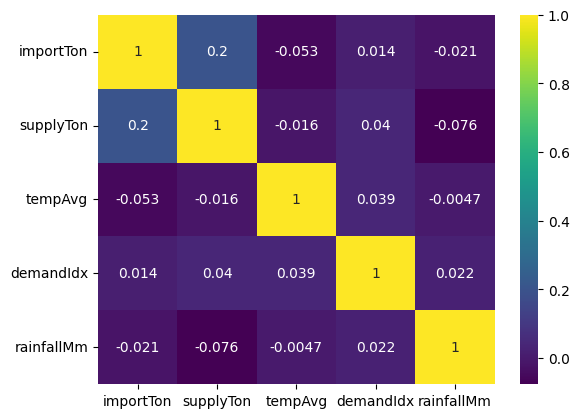

In [11]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

sns.heatmap(df[['importTon', 'supplyTon', 'tempAvg', 'demandIdx', 'rainfallMm']].corr(), annot=True, cmap='viridis')
plt.show()

In [ ]:
# (4) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요

정답04 = 'cmap'


<details><summary>힌트 1단계 (접근 방향) - 4번 문항</summary>

상관계수 행렬을 색으로 표현하는 그래프입니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 4번 문항</summary>

사용할 도구: `.corr()`, `sns.heatmap`. 정답은 4글자이고 첫 글자는 `c` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 4번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(df[['importTon', 'supplyTon', 'tempAvg', 'demandIdx', 'rainfallMm']].corr(), annot=True, cm__='viridis')
plt.show()

정답04 = 'cm__'   # 빈칸에 넣은 단어
```

</details>

## <font color=blue>**<데이터 전처리 (30점)>**</font>

### **5. 그래프로 확인한 결과, 반입 물량(톤)(supplyTon) 컬럼에서 이상치가 발견되었습니다. AI모델링할 때 부정적 영향이 없도록 다음 지침에 따라 이상치를 처리하세요.**

<sub>학습 목표: 사분위 범위(IQR) 등의 기준으로 이상치를 찾아 처리할 수 있다 | 역량: DP1 이상치 처리 | 기술: pandas(quantile, drop, reset_index) | 난이도: 쉬움 | 예상 시간: 6분</sub>

- 앞 문항 결과 사용 : 2번 `df`
- 대상 데이터프레임 : df
- 반입 물량(톤)(supplyTon)이(가) upper fence 값보다 크거나 lower fence 값보다 작은 이상치 행(row)을 삭제하세요 (IQR 기준 K=3.0)
- AI모델링에 불필요한 표본 식별번호(sampleId) 컬럼을 삭제하세요
- 전처리를 적용한 데이터프레임은 df_temp 라는 변수명으로 보관하세요
- 아래 코드 셀의 빈칸 `< blank05_1 >`, `< blank05_2 >` 를 채우고 실행하세요
- 빈칸에 들어갈 내용(함수·인자·모듈 이름)을 코드 셀 맨 아래 `정답05_1`, `정답05_2` 변수에 각각 저장하세요
    - 예시) 정답05_0 = 'data'
- 배점 : 6점

---

In [12]:
# (코드 셀) 코드의 빈칸(< blank >)을 채우고, 맨 아래 정답 변수에 빈칸의 내용을 입력한 뒤 실행하세요

q1 = df['supplyTon'].quantile(0.25)
q3 = df['supplyTon'].quantile(0.75)
iqr = q3 - q1

lower_fence = q1 - 3.0 * iqr
upper_fence = q3 + 3.0 * iqr

df_temp = df.drop( df[(df['supplyTon'] > upper_fence) | (df['supplyTon'] < lower_fence)].index, axis=0)
df_temp = df_temp.drop(columns=['sampleId'])
df_temp.reset_index(drop=True, inplace=True)


In [ ]:
# (5) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요

정답05_1 = 'quantile'
정답05_2 = 'drop'


<details><summary>힌트 1단계 (접근 방향) - 5번 문항</summary>

빈칸을 채워 코드를 완성한 뒤 실행하세요. 행이나 열을 삭제하는 DataFrame 메서드입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 5번 문항</summary>

사용할 도구: `drop`, `quantile`, `reset_index`. 정답은 4글자이고 첫 글자는 `d` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 5번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
q1 = df['supplyTon'].quan____(0.25)
q3 = df['supplyTon'].quantile(0.75)
iqr = q3 - q1

lower_fence = q1 - 3.0 * iqr
upper_fence = q3 + 3.0 * iqr

df_temp = df.dr__( df[(df['supplyTon'] > upper_fence) | (df['supplyTon'] < lower_fence)].index, axis=0)
df_temp = df_temp.drop(columns=['sampleId'])
df_temp.reset_index(drop=True, inplace=True)

정답05_1 = 'quan____'   # 빈칸 1에 넣은 단어
정답05_2 = 'dr__'   # 빈칸 2에 넣은 단어
```

</details>

### **6. 제시된 가이드에 맞춰 결측치를 처리하고 검증하는데 에러가 나고 있습니다. 코드의 오류를 정정하세요.**

<sub>학습 목표: 결측치를 확인하고 삭제하거나 대체할 수 있다 | 역량: DP2 결측치 처리 | 기술: pandas(dropna, sum, isnull) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 5번 `df_temp`
- 코드의 오류를 수정하세요
    - 대상 데이터프레임 : df_temp
    - 결측치 개수를 확인한 뒤, 결측치가 있는 행을 모두 삭제해 df_na 에 보관하세요
    - 처리 후 결측치가 사라졌는지 확인하세요
- **[정답06]** 처리 전 df_temp 의 결측치는 총 몇 개인가요?
- 답안 : **[정답06]** 의 값만 코드 셀 맨 아래에 `정답06 = 값` 형태로 입력하세요
- 오류는 4곳입니다 — 실행 오류뿐 아니라 실행은 되지만 가이드와 다르게 동작하는 부분도 바로잡으세요
- 배점 : 6점

---

In [16]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

print('결측치 처리 전\n', df_temp.isnull().sum())
df_na = df_temp.dropna()
print('결측치 처리 후\n', df_na.isnull().sum())

df_temp.isnull().sum().sum()


결측치 처리 전
 priceTrend      0
rainfallMm      0
sunshineH       0
tempAvg        39
supplyTon       0
stockTon        0
importTon       0
demandIdx       0
fuelCost        0
holidayDays     0
pestIdx        57
origin          0
grade          41
market          0
sizeClass       0
dtype: int64
결측치 처리 후
 priceTrend     0
rainfallMm     0
sunshineH      0
tempAvg        0
supplyTon      0
stockTon       0
importTon      0
demandIdx      0
fuelCost       0
holidayDays    0
pestIdx        0
origin         0
grade          0
market         0
sizeClass      0
dtype: int64


np.int64(137)

In [ ]:
# (6) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요

정답06 = '137'


<details><summary>힌트 1단계 (접근 방향) - 6번 문항</summary>

고칠 곳은 4군데입니다. 실행 오류뿐 아니라 실행은 되지만 가이드와 다르게 동작하는 줄도 찾으세요. 결측치 확인 -> 삭제 -> 재확인 순서로 코드를 읽어 보세요. 결측치 처리 전 데이터프레임의 결측치 합계를 구하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 6번 문항</summary>

사용할 도구: `isnull`, `sum`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 6번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
print('결측치 처리 전\n', df_temp.isnull().sum())
df_na = df_temp.dropna()
print('결측치 처리 후\n', df_na.isnull().sum())

# [정답06] 실행한 결과를 입력하세요
df_temp.isnull().sum().sum()
```

</details>

### **7. 규모 구분(sizeClass)는 순서가 있는 범주입니다. 순서를 반영해 인코딩하세요.**

<sub>학습 목표: 범주형 변수를 인코딩하고 변수를 정리·변환할 수 있다 | 역량: DP3 인코딩·변수 변환 | 기술: pandas(copy, get_dummies) · scikit-learn(OrdinalEncoder, fit_transform) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 1번 `pd` · 6번 `df_na`
- 다음 지침에 따라 코드를 작성하고 실행하세요
    - 대상 데이터프레임 : df_na
    - sizeClass 는 OrdinalEncoder 를 사용하고, 순서(categories)는 소 < 중 < 대 로 할당하세요
    - 나머지 문자열 컬럼 origin, grade, market 은(는) get_dummies(drop_first=True)로 인코딩하세요
    - 결과는 df_enc 에 저장하세요
- **[정답07]** 인코딩된 sizeClass 의 **평균**을 소수점 둘째 자리까지 입력하세요
- 답안 : **[정답07]** 의 값만 코드 셀 맨 아래에 `정답07 = 값` 형태로 입력하세요
- 배점 : 6점

---

In [17]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

from sklearn.preprocessing import OrdinalEncoder

df_enc = df_na.copy()
oe = OrdinalEncoder(categories=[['소', '중', '대']])
df_enc[['sizeClass']] = oe.fit_transform(df_enc[['sizeClass']])
df_enc = pd.get_dummies(data=df_enc, columns=['origin', 'grade', 'market'], drop_first=True)

round(df_enc['sizeClass'].mean(), 2)


np.float64(1.03)

In [ ]:
# (7) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요

정답07 = '1.03'


<details><summary>힌트 1단계 (접근 방향) - 7번 문항</summary>

순서가 있는 범주는 순서 목록을 직접 알려 주는 인코더를 씁니다. 인코딩된 컬럼의 평균을 구하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 7번 문항</summary>

사용할 도구: `OrdinalEncoder`, `categories`, `mean`, `round`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 7번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import pandas as pd

from sklearn.preprocessing import OrdinalEncoder

df_enc = df_na.copy()
oe = OrdinalEncoder(categories=[['소', '중', '대']])
df_enc[['sizeClass']] = oe.fit_transform(df_enc[['sizeClass']])
df_enc = pd.get_dummies(data=df_enc, columns=['origin', 'grade', 'market'], drop_first=True)

# [정답07] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
round(df_enc['____'].mean(), __)
```

</details>

### **8. 훈련과 검증 데이터셋을 분리하고, 분리된 데이터의 크기를 확인할 계획입니다.**

<sub>학습 목표: 피처와 레이블을 나누고 훈련·검증 데이터로 분할할 수 있다 | 역량: DP4 데이터 분할 | 기술: pandas(drop) · scikit-learn(train_test_split) | 난이도: 쉬움 | 예상 시간: 8분</sub>

- 앞 문항 결과 사용 : 7번 `df_enc`
- 다음 지침에 따라 코드를 작성하고 실행하세요
    - 대상 데이터프레임 : df_enc
    - 시세 추세(priceTrend) 컬럼을 레이블값 y 로, 나머지 컬럼을 피처값 X 로 대입하세요
    - 분리 결과는 X_train, X_valid, y_train, y_valid 순서로 받으세요
    - 훈련 80%, 검증 20% 비율로 나누세요 (test_size=0.2)
    - 레이블 분포가 훈련·검증에서 같도록 stratify 옵션을 지정하세요
    - scikit-learn 의 train_test_split 함수를 활용하세요
    - random_state 는 42 로 고정하세요
- **[결과 변수]** 결과는 반드시 `X_valid` 변수에 저장하세요 — 변수의 내용(모양·값)으로 채점합니다
- 확인 : 코드 셀 맨 아래 확인 줄(`print(len(X_valid))`)을 실행하세요. LMS 에서는 이 출력값을 입력합니다
- 배점 : 6점

---

In [22]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

# [8번 확인] 결과 변수 `X_valid` 확인 — LMS 에는 이 출력값을 입력하세요

from sklearn.model_selection import train_test_split

X = df_enc.drop('priceTrend', axis=1)
y = df_enc['priceTrend']

X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(len(X_valid))

128


In [ ]:
# (8) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
128

<details><summary>힌트 1단계 (접근 방향) - 8번 문항</summary>

피처와 레이블을 나눈 뒤, 훈련/검증으로 무작위 분할합니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 8번 문항</summary>

사용할 도구: `train_test_split`, `drop`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 8번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 결과는 `X_valid` 변수에 저장되고, 마지막 줄의 출력이 확인값입니다.
```python
from sklearn.model_selection import train_test_split

X = df_enc.drop('priceTrend', axis=1)
y = df_enc['priceTrend']

X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# [X_valid] 결과 확인 (LMS 에는 이 출력값을 입력)
print(len(X_valid))
```

</details>

### **9. 스케일링을 통해 변수들의 단위(범위) 차이가 모델에 미치는 영향을 줄이려 합니다. (최솟값 0~최댓값 1 정규화)**

<sub>학습 목표: 훈련 데이터로 스케일러를 학습해 검증 데이터에 같은 기준을 적용할 수 있다 | 역량: DP5 스케일링 | 기술: scikit-learn(MinMaxScaler, fit_transform, transform) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `X_train`, `X_valid`
- 아래 안내대로 스케일링 처리하는데 실행 중 예외가 발생합니다. 코드의 오류를 바로잡으세요
    - sklearn.preprocessing 에서 MinMaxScaler 를 import 하세요
    - MinMaxScaler 를 scaler 변수에 할당하세요
    - 훈련 데이터(X_train)에 대해 스케일러를 학습시키고 변환을 적용해 X_train 에 다시 보관하세요
    - 검증 데이터(X_valid)에는 **학습된 기준을 그대로** 적용(변환만)해 X_valid 에 담으세요
- **[정답09]** MinMaxScaler 적용 후 검증 데이터(X_valid)의 **최솟값**을 소수점 둘째 자리까지 작성하세요
- 답안 : **[정답09]** 의 값만 코드 셀 맨 아래에 `정답09 = 값` 형태로 입력하세요
- 오류는 2곳입니다 — 실행 오류뿐 아니라 실행은 되지만 가이드와 다르게 동작하는 부분도 바로잡으세요
- 배점 : 6점

---

In [23]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

import numpy as np

from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_valid = scaler.transform(X_valid)

round(np.min(X_valid), 2)


np.float64(-0.02)

In [ ]:
# (9) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요

정답09 = '-0.02'


<details><summary>힌트 1단계 (접근 방향) - 9번 문항</summary>

고칠 곳은 2군데입니다. 실행 오류뿐 아니라 실행은 되지만 가이드와 다르게 동작하는 줄도 찾으세요. 훈련 데이터로 fit, 검증 데이터는 transform 만 하는 규칙을 떠올리세요. 변환된 검증 데이터 전체에서 최솟값을 구하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 9번 문항</summary>

사용할 도구: `np.min`, `round`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 9번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import numpy as np

from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_valid = scaler.transform(X_valid)

# [정답09] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
round(np.min(X_valid), __)
```

</details>

## <font color=blue>**<AI 모델링 (50점)>**</font>

### **10. 시세 추세(priceTrend)을(를) 예측하는 머신러닝 모델을 만들려고 합니다. KNN와(과) RandomForest는 각각 서로 다른 방식으로 예측하는 모델입니다.**

<sub>학습 목표: 머신러닝 모델에 하이퍼파라미터를 지정해 학습하고 결과를 확인할 수 있다 | 역량: AM1 머신러닝 모델 학습·탐색 | 기술: scikit-learn(KNeighborsClassifier, fit, RandomForestClassifier) | 난이도: 쉬움 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `y_train` · 9번 `X_train`
- KNN 모델을 아래와 같이 만들어 `knn` 변수에 저장하고 학습시키세요
    - 하이퍼파라미터 : n_neighbors=15, weights='distance'
    - 앞서 분리한 훈련데이터셋(X_train, y_train)으로 fit 함수를 사용해 학습시키세요
- RandomForest 모델을 아래와 같이 만들어 `rf` 변수에 저장하고 학습시키세요
    - 하이퍼파라미터 : n_estimators=100, max_depth=6
    - 난수 시드(random_state) : 1
    - 앞서 분리한 훈련데이터셋(X_train, y_train)으로 fit 함수를 사용해 학습시키세요
- **[정답10]** 학습된 `rf`(RandomForest) 의 **훈련 데이터** 점수 `rf.score(X_train, y_train)` (정확도(accuracy))를 소수점 셋째 자리까지 작성하세요
- 답안 : **[정답10]** 의 값만 코드 셀 맨 아래에 `정답10 = 값` 형태로 입력하세요
- 배점 : 10점

---

In [24]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=15, weights='distance')
knn.fit(X_train, y_train)

from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=1)
rf.fit(X_train, y_train)

round(rf.score(X_train, y_train), 3)


0.888

In [ ]:
# (10) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요

정답10 = '0.888'


<details><summary>힌트 1단계 (접근 방향) - 10번 문항</summary>

모델 객체를 하이퍼파라미터와 함께 만들고 훈련 데이터로 fit 합니다. 학습된 모델의 score 메서드에 훈련 데이터를 넣고 반올림하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 10번 문항</summary>

사용할 도구: `KNeighborsClassifier`, `fit`, `RandomForestClassifier`, `score`, `round`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 10번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=15, weights='distance')
knn.fit(X_train, y_train)

from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=1)
rf.fit(X_train, y_train)

# [정답10] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
round(rf.score(X_train, y_train), __)
```

</details>

### **11. RandomForest 모델이 예측에 가장 크게 쓴 변수가 무엇인지 확인하려 합니다.**

<sub>학습 목표: 변수 중요도·계수로 모델이 어떤 변수에 의존하는지 해석할 수 있다 | 역량: AM2 모델 해석 | 기술: pandas(Series, idxmax, columns) · scikit-learn(feature_importances_) | 난이도: 쉬움 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 1번 `pd` · 8번 `X` · 10번 `rf`
- 학습된 RandomForest 모델 `rf` 의 변수중요도를 변수명(X.columns)을 인덱스로 하는 Series `fi` 로 만들고, 가장 큰 값의 변수명을 `idxmax()` 로 구해 `top_feature` 에 보관하세요
- **[정답11]** `top_feature` 의 값(변수명)을 기입하세요
- 답안 : **[정답11]** 의 값만 코드 셀 맨 아래에 `정답11 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 10점

---

In [25]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

fi = pd.Series(rf.feature_importances_, index=X.columns)
top_feature = fi.idxmax()

top_feature

print(top_feature)


demandIdx


In [ ]:
# (11) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요

정답11 = 'demandIdx'


<details><summary>힌트 1단계 (접근 방향) - 11번 문항</summary>

중요도 배열에 변수 이름 인덱스를 붙여 Series 로 만든 뒤 최댓값의 이름을 구합니다. top_feature 를 출력하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 11번 문항</summary>

사용할 도구: `pd.Series`, `feature_importances_`, `idxmax`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 11번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import pandas as pd

fi = pd.Series(rf.feature_importances_, index=X.columns)
top_feature = fi.idxmax()

# [정답11] 실행한 결과를 입력하세요
print(top_feature)
```

</details>

### **12. 앞서 학습시킨 KNN와(과) RandomForest 모델의 성능을 평가하려고 합니다.**

<sub>학습 목표: 평가 지표로 두 모델의 성능을 비교할 수 있다 | 역량: AM3 모델 성능 평가 | 기술: scikit-learn(predict, accuracy_score) | 난이도: 쉬움 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `y_valid` · 9번 `X_valid` · 10번 `knn`, `rf`
- 제시된 가이드에 맞춰 각 모델의 Accuracy(정확도) 를 산출하려는데 에러가 나고 있습니다. 코드의 오류를 수정하세요
    - 앞서 학습시킨 knn 와 rf 모델을 사용하세요
    - 성능 평가는 **검증데이터셋(X_valid, y_valid)** 을 활용하세요
    - 두 모델의 Accuracy(정확도) 값을 각각 knn_score, rf_score 변수에 저장하고 출력하세요
- **[정답12]** 두 모델의 Accuracy(정확도) 결과를 비교했을 때, 성능이 **더 우수한** 모델은 무엇인가요? (KNN / RandomForest 중 하나)
- 답안 : **[정답12]** 의 값만 코드 셀 맨 아래에 `정답12 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 오류는 3곳입니다 — 실행 오류뿐 아니라 실행은 되지만 가이드와 다르게 동작하는 부분도 바로잡으세요
- 배점 : 10점

---

In [27]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

from sklearn.metrics import accuracy_score

y_pred_knn = knn.predict(X_valid)
y_pred_rf = rf.predict(X_valid)

knn_score = accuracy_score(y_valid, y_pred_knn)
rf_score = accuracy_score(y_valid, y_pred_rf)
print(knn_score, rf_score)



0.5625 0.625


In [ ]:
# (12) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요

정답12 = 'RandomForest'


<details><summary>힌트 1단계 (접근 방향) - 12번 문항</summary>

고칠 곳은 3군데입니다. 실행 오류뿐 아니라 실행은 되지만 가이드와 다르게 동작하는 줄도 찾으세요. Accuracy(정확도) 를 계산하는 흐름(예측 -> 지표 함수)을 점검하세요. 값이 클수록 우수한 지표입니다. 두 점수를 비교하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 12번 문항</summary>

가이드에 언급된 함수를 확인하세요.

</details>

<details><summary>힌트 3단계 (전체 코드) - 12번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
from sklearn.metrics import accuracy_score

y_pred_knn = knn.predict(X_valid)
y_pred_rf = rf.predict(X_valid)

knn_score = accuracy_score(y_valid, y_pred_knn)
rf_score = accuracy_score(y_valid, y_pred_rf)
print(knn_score, rf_score)

# [정답12] 실행한 결과를 입력하세요
print(knn_score, rf_score)
```

</details>

> **<span style="color:red">다음 문항을 풀기 전에 </span>아래 코드를 실행하세요. (tensorflow 필요)**

In [28]:
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model, load_model
from tensorflow.keras.layers import Input, Dense, Activation, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam, RMSprop, Nadam, SGD
from tensorflow.keras.regularizers import l2
from tensorflow.keras.utils import to_categorical

tf.random.set_seed(1)

### **13. 시세 추세(priceTrend)을(를) 예측하는 딥러닝 모델을 만들려고 합니다. 아래 가이드를 참고해서 모델링하고 학습을 수행하십시오.**

<sub>학습 목표: 주어진 구조대로 Keras 딥러닝 모델을 구성하고 학습할 수 있다 | 역량: AM4 딥러닝 모델 구성·학습 | 기술: pandas(shape) · TensorFlow(Keras)(to_categorical, Input, Model, EarlyStopping) | 난이도: 최상 | 예상 시간: 19분</sub>

- 앞 문항 결과 사용 : 8번 `y_train`, `y_valid` · 9번 `X_train`
- 아래 **모델 구조도(topology)** 와 가이드를 함께 참고하세요
- 아래 조건대로 모델을 구현하고 학습하세요
    - TensorFlow(Keras) 로 구현하세요
    - Sequential 이 아니라 **함수형 API**로 구성하세요: `Input(shape=(X_train.shape[1],))` 로 입력을 만들고, 각 층을 `층(앞 텐서)` 형태로 이어 붙인 뒤 `Model(inputs=..., outputs=...)` 로 `model` 을 만드세요
    - 은닉층은 Dense 레이어 1개(노드 수 [64]), 활성화 함수는 'relu' 로 하세요
    - 각 Dense 층 뒤에 BatchNormalization 층을 추가하세요
    - EarlyStopping 으로 5번의 epoch 동안 val_loss 가 향상되지 않으면 훈련을 중지(restore_best_weights=True)하도록 설정하고 estop 변수에 보관하세요 / 첫 은닉층 바로 다음에 Dropout(0.3) 을 추가하세요
    - 출력층: 노드 3개, 활성화 함수 'softmax'
    - optimizer 는 nadam, loss 는 categorical_crossentropy, metrics 는 [accuracy] 로 지정해서 모델을 컴파일하세요
    - batch_size 는 16, epochs 는 200 로 학습하고 학습정보는 history 변수에 저장하세요 (검증은 훈련 데이터의 20% 를 쓰는 validation_split=0.2 로 지정)
    - 가이드에 없는 인자는 추가하지 말고 기본값으로 두세요
- **[결과 변수]** 모델은 `model`, 학습 기록은 `history` 변수에 저장하세요 — 모델 구조(층 수·파라미터 수)와 학습 설정으로 채점합니다
- 확인 : 코드 셀 맨 아래 `print(model.count_params())` 출력값을 LMS 에 입력합니다
- 배점 : 10점

---

**[모델 구조도]**

![topology.png](attachment:topology.png)

In [29]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

y_train_cat = to_categorical(y_train)
y_valid_cat = to_categorical(y_valid)

inputs = Input(shape=(X_train.shape[1],))
x = Dense(64, activation='relu')(inputs)
x = BatchNormalization()(x)
x = Dropout(0.3)(x)
outputs = Dense(3, activation='softmax')(x)
model = Model(inputs=inputs, outputs=outputs)

estop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
cb_list = [estop]

model.compile(optimizer='nadam', loss='categorical_crossentropy', metrics=['accuracy'])

history = model.fit(X_train, y_train_cat,
                    epochs=200, batch_size=16,
                    validation_split=0.2,
                    callbacks=cb_list)

print(model.count_params())

Epoch 1/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.3725 - loss: 1.4365 - val_accuracy: 0.4369 - val_loss: 1.0806
Epoch 2/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4265 - loss: 1.2288 - val_accuracy: 0.4369 - val_loss: 1.0572
Epoch 3/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4583 - loss: 1.1156 - val_accuracy: 0.4369 - val_loss: 1.0456
Epoch 4/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4926 - loss: 1.0345 - val_accuracy: 0.4369 - val_loss: 1.0378
Epoch 5/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5123 - loss: 1.0325 - val_accuracy: 0.4369 - val_loss: 1.0303
Epoch 6/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5466 - loss: 0.9649 - val_accuracy: 0.4369 - val_loss: 1.0200
Epoch 7/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6127 - loss: 0.8950 - val_accuracy: 0.4466 - val_loss: 1.0079
Epoch 8/200
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5980 - loss: 0.8556 - val_accuracy: 0.4369 - v

In [ ]:
# (13) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요
1795

<details><summary>힌트 1단계 (접근 방향) - 13번 문항</summary>

입력 텐서를 만들고, 층을 하나씩 앞 텐서에 적용해 이어 붙이세요. 마지막에 Model 로 묶습니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 13번 문항</summary>

사용할 도구: `Input`, `Dense`, `Dropout`, `Model`, `EarlyStopping`, `model.compile`, `model.fit`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 13번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 결과는 `model` 변수에 저장되고, 마지막 줄의 출력이 확인값입니다.
```python
y_train_cat = to_categorical(y_train)
y_valid_cat = to_categorical(y_valid)

inputs = Input(shape=(X_train.shape[1],))
x = Dense(64, activation='relu')(inputs)
x = BatchNormalization()(x)
x = Dropout(0.3)(x)
outputs = Dense(3, activation='softmax')(x)
model = Model(inputs=inputs, outputs=outputs)

estop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
cb_list = [estop]

model.compile(optimizer='nadam', loss='categorical_crossentropy', metrics=['accuracy'])

history = model.fit(X_train, y_train_cat,
                    epochs=200, batch_size=16,
                    validation_split=0.2,
                    callbacks=cb_list)

# [model] 결과 확인 (LMS 에는 이 출력값을 입력)
print(model.count_params())
```

</details>

### **14. 앞서 만든 딥러닝 모델의 일반화 성능을 평가하려고 합니다. matplotlib 라이브러리를 활용해서, 학습 Accuracy와(과) 검증 Accuracy의 변화를 그래프로 시각화하십시오.**

<sub>학습 목표: 학습 기록으로 딥러닝 모델의 학습 과정과 성능을 분석할 수 있다 | 역량: AM5 딥러닝 학습 결과 분석 | 기술: matplotlib(plot, title, xlabel, ylabel) · TensorFlow(Keras)(history) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 13번 `history`
- 학습 Accuracy 과 검증 Accuracy 를 한 그래프(1개)에 함께 그리세요
- 그래프의 타이틀은 'Model Accuracy' 로, X축 이름은 'Epochs', Y축 이름은 'Accuracy' 로 표시하세요
- 두 선의 범례 : 'train', 'val'
- 아래 코드 셀의 빈칸 `< blank14_1 >`, `< blank14_2 >` 를 채우고 실행하세요
- 빈칸에 들어갈 내용(함수·인자·모듈 이름)을 코드 셀 맨 아래 `정답14_1`, `정답14_2` 변수에 각각 저장하세요
    - 예시) 정답14_0 = 'data'
- 배점 : 10점

---

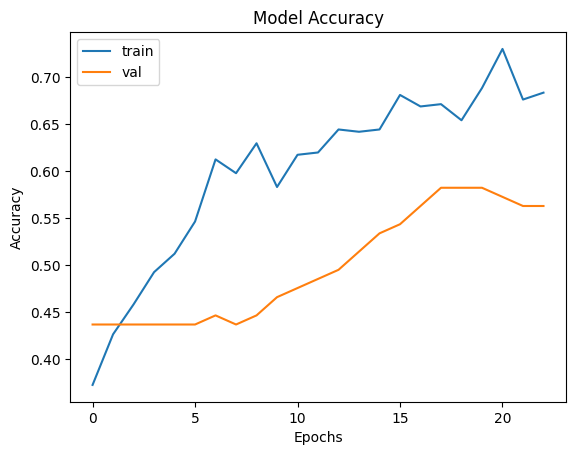

In [30]:
# (코드 셀) 코드의 빈칸(< blank >)을 채우고, 맨 아래 정답 변수에 빈칸의 내용을 입력한 뒤 실행하세요

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(['train', 'val'])
plt.show()


In [ ]:
# (14) 자동 채점 — 답을 입력·실행한 뒤 이 셀을 실행하세요

정답14_1 = 'history'
정답14_2 = 'legend'


<details><summary>힌트 1단계 (접근 방향) - 14번 문항</summary>

빈칸을 채워 코드를 완성한 뒤 실행하세요. 범례를 표시하는 matplotlib 함수입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 14번 문항</summary>

사용할 도구: `plt.plot`, `plt.title`, `plt.xlabel`, `plt.ylabel`, `plt.legend`, `plt.show`. 정답은 6글자이고 첫 글자는 `l` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 14번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import matplotlib.pyplot as plt

plt.plot(hist___.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.leg___(['train', 'val'])
plt.show()

정답14_1 = 'hist___'   # 빈칸 1에 넣은 단어
정답14_2 = 'leg___'   # 빈칸 2에 넣은 단어
```

</details>

### 전체 자동 채점

In [ ]:
# 모든 문항을 한 번에 채점합니다
채점()

### **모든 문항이 완료되었습니다. 수고하셨습니다.**
### 답안을 저장한 뒤 제출해 주시기 바랍니다.